# Exploratory Data Analysis — AG News Dataset

**Dataset:** `data/raw/dataset.parquet`  
**Rows:** 127,600  
**Classes:** World, Sports, Business, Sci/Tech (balanced, 31,900 each)  
**Source:** HuggingFace — `ag_news`

This notebook covers:
1. Basic statistics and schema
2. Class distribution
3. Text length distributions (chars and words)
4. Top-20 most frequent words (stopwords removed)
5. Source distribution

In [1]:
import re
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

STOPWORDS = set(stopwords.words('english'))
PALETTE = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

BASE_DIR = Path('..').resolve()
DATA_PATH = BASE_DIR / 'data' / 'raw' / 'dataset.parquet'
PLOTS_DIR = BASE_DIR / 'reports' / 'eda_plots'

df = pd.read_parquet(DATA_PATH)
df['text_len'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

print('Loaded:', df.shape)
df.head(3)

Loaded: (127600, 6)


,text,label,source,collected_at,text_len,word_count
0,Wall St. Bears Claw Back Into the Black (Reute...,Business,huggingface:ag_news,2026-03-21T16:57:22.320144+00:00,144,21
1,Carlyle Looks Toward Commercial Aerospace (Reu...,Business,huggingface:ag_news,2026-03-21T16:57:22.320144+00:00,266,36
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,Business,huggingface:ag_news,2026-03-21T16:57:22.320144+00:00,232,36


## 1. Basic Statistics & Schema

In [2]:
print('Shape:', df.shape)
print()
print('Dtypes:')
print(df.dtypes)
print()
print('Missing values:')
print(df.isnull().sum())

Shape: (127600, 6)

Dtypes:
text              str
label             str
source            str
collected_at      str
text_len        int64
word_count      int64
dtype: object

Missing values:
text            0
label           0
source          0
collected_at    0
text_len        0
word_count      0
dtype: int64


In [3]:
summary = pd.DataFrame({
    'Metric': [
        'Total rows', 'Columns', 'Classes', 'Rows per class',
        'Unique sources', 'Missing values',
        'Avg text length (chars)', 'Median text length (chars)',
        'Avg word count', 'Median word count',
    ],
    'Value': [
        f"{len(df):,}", str(df.shape[1] - 2), str(df['label'].nunique()),
        f"{len(df) // df['label'].nunique():,}",
        str(df['source'].nunique()), str(df.isnull().sum().sum()),
        f"{df['text_len'].mean():.1f}", f"{df['text_len'].median():.0f}",
        f"{df['word_count'].mean():.1f}", f"{df['word_count'].median():.0f}",
    ],
})
summary

,Metric,Value
0,Total rows,"127,600"
1,Columns,4
2,Classes,4
3,Rows per class,"31,900"
4,Unique sources,1
5,Missing values,0
6,Avg text length (chars),236.4
7,Median text length (chars),232
8,Avg word count,37.8
9,Median word count,37


## 2. Class Distribution

The dataset is **perfectly balanced** — each of the four classes contributes exactly 31,900 samples (25%).  
This means no class-weighting is needed for baseline models.

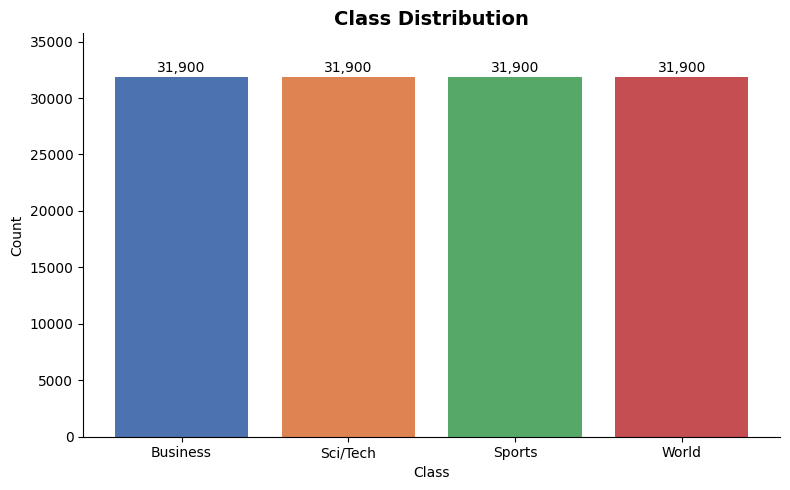

In [4]:
label_counts = df['label'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(label_counts.index, label_counts.values, color=PALETTE)
for bar, val in zip(bars, label_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 150,
            f'{val:,}', ha='center', va='bottom', fontsize=10)
ax.set_title('Class Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.set_ylim(0, label_counts.max() * 1.12)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

## 3. Text Length Distribution

Texts are relatively short news snippets. The character length is tightly distributed around 230 chars (~38 words),  
with a long right tail from a few longer articles (up to 1,012 chars / 177 words).

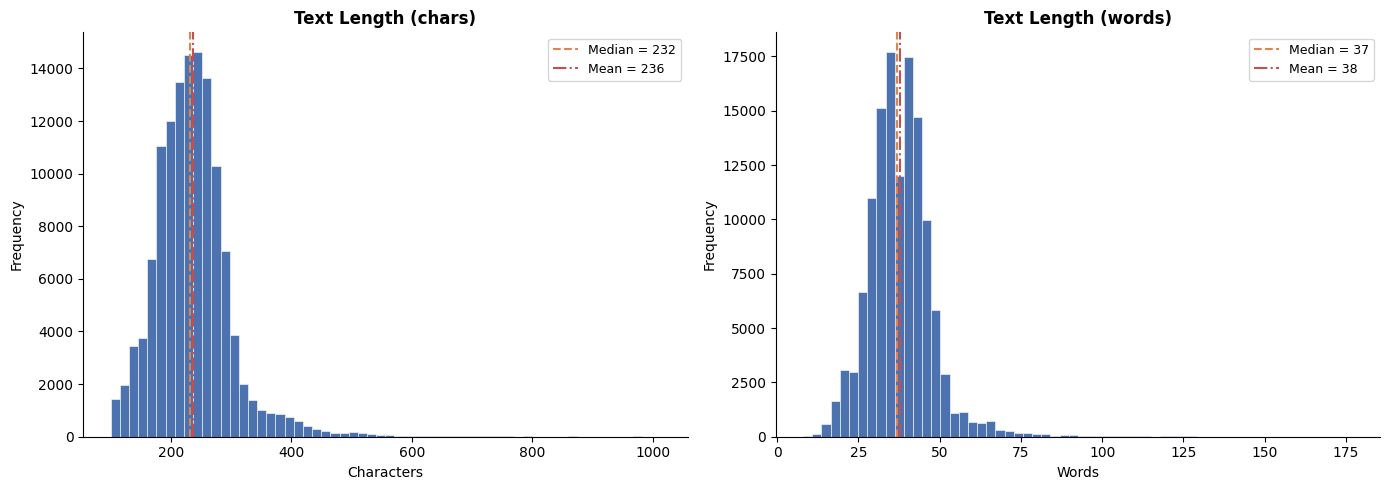

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, xlabel, title in [
    (axes[0], 'text_len', 'Characters', 'Text Length (chars)'),
    (axes[1], 'word_count', 'Words', 'Text Length (words)'),
]:
    ax.hist(df[col], bins=60, color='#4C72B0', edgecolor='white', linewidth=0.4)
    ax.axvline(df[col].median(), color='#DD8452', linestyle='--', linewidth=1.5,
               label=f'Median = {df[col].median():.0f}')
    ax.axvline(df[col].mean(), color='#C44E52', linestyle='-.', linewidth=1.5,
               label=f'Mean = {df[col].mean():.0f}')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Frequency')
    ax.legend(fontsize=9)
    sns.despine(ax=ax)

plt.tight_layout()
plt.show()

## 4. Top-20 Most Frequent Words (stopwords removed)

After removing English stopwords, the dominant terms are newswire attribution words (`reuters`, `quot`) and  
temporal/political keywords (`iraq`, `oil`, `york`, `world`). These reflect the 2004-era AG News corpus origin.

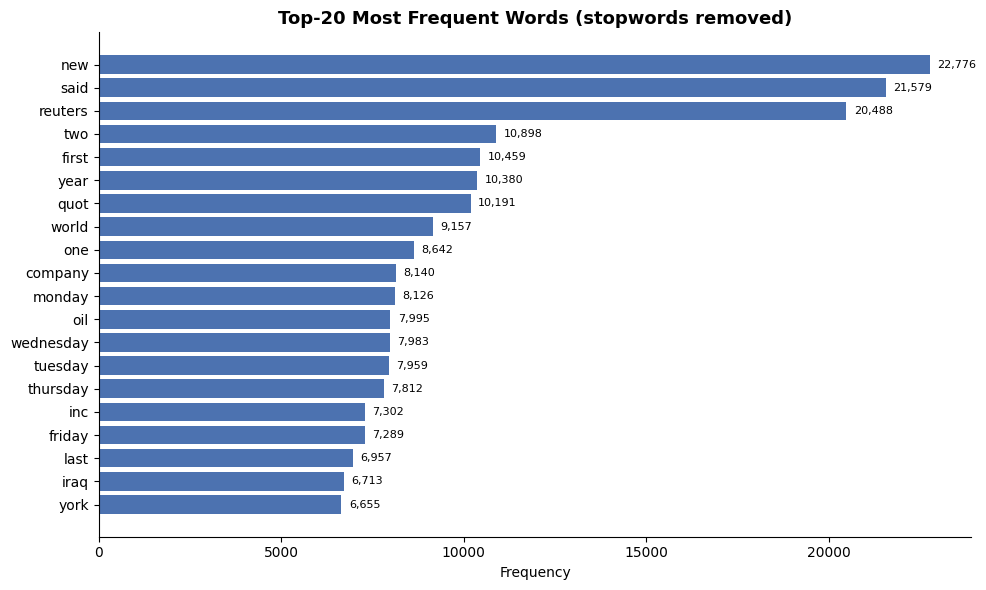

Vocabulary size (no stopwords): 62,472


In [6]:
def tokenize(text):
    tokens = re.findall(r'\b[a-z]+\b', text.lower())
    return [t for t in tokens if t not in STOPWORDS and len(t) > 2]

word_freq = Counter()
for text in df['text']:
    word_freq.update(tokenize(text))

top20 = word_freq.most_common(20)
words, counts = zip(*top20)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(words[::-1], counts[::-1], color='#4C72B0')
ax.set_title('Top-20 Most Frequent Words (stopwords removed)', fontsize=13, fontweight='bold')
ax.set_xlabel('Frequency')
for bar, val in zip(bars, counts[::-1]):
    ax.text(bar.get_width() + 200, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=8)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

print(f'Vocabulary size (no stopwords): {len(word_freq):,}')

## 5. Source Distribution

All 127,600 rows originate from a single source: `huggingface:ag_news`.  
No source-level stratification is needed.

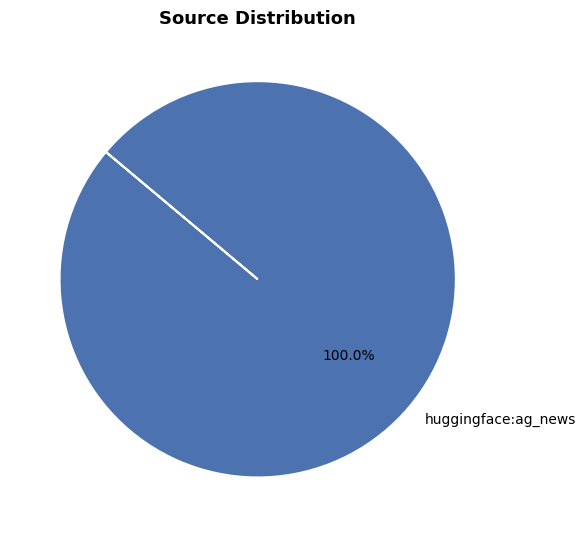

In [7]:
source_counts = df['source'].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    source_counts.values,
    labels=source_counts.index,
    autopct='%1.1f%%',
    colors=PALETTE[:len(source_counts)],
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
    startangle=140,
)
ax.set_title('Source Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Summary

| Finding | Detail |
|---|---|
| Perfectly balanced classes | 31,900 rows per class — no class weights needed |
| No missing values | All 4 columns complete |
| Short texts | Mean ~236 chars / ~38 words; tight distribution |
| Right-skewed length tail | Max 1,012 chars; some outliers worth inspecting |
| Vocabulary | 62,472 unique tokens (after stopword removal) |
| Single source | 100% from `huggingface:ag_news` |
| Top terms | `reuters`, `quot` (wire attribution), `iraq`, `oil`, `york` |
| `collected_at` | All timestamps identical — metadata field, not useful for modeling |